# Do school size and staffing add to socioeconomic predictors of school ACT scores?
## Introduction and Research question
School-level ACT averages may reflect both the socioeconomic circumstances of the communities schools serve and characteristics of the schools themselves. This report examines whether socioeconomic indicators predict average school ACT scores and whether adding school enrollment and the student–teacher ratio improves the model.

**Is average school ACT score predicted by socioeconomic factors, and do school size (enrollment) and staffing (students per teacher) add predictive power beyond those factors?**
## Why these predictors
EdGap's variables (unemployment, adult education, married-couple families, median income, free/reduced lunch) describe the *community* around a school. Enrollment and student-teacher ratio describe the *school's own resources*, which districts can change, unlike neighborhood income. If they add little, ACT gaps are mostly about community context. If they add a lot, school-level choices matter too.
## Data
- `EdGap_data.xlsx`: ACT and census-tract socioeconomic variables
- `ccd_sch_029_1617_w_1a_11212017.csv`: NCES school directory (2016-17)
- `ccd_sch_052_1617_w_1a_11212017.csv`: NCES school membership, used for enrollment
- `ccd_sch_059_1617_w_1a_11212017.csv`: NCES school staff, used for teacher counts


In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

## Load the data
The next cells load the EdGap, NCES school-directory, membership, and staff files.

In [144]:
edgap = pd.read_excel('/Users/anush/Documents/DATA 5100/education/data/EdGap_data.xlsx', dtype = {'NCESSCH School ID': object})

/Users/anush/.conda/envs/notebook-env/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [145]:
school_information = pd.read_csv(
    '/Users/anush/Documents/DATA 5100/education/data/ccd_sch_029_1617_w_1a_11212017.csv',
    encoding = 'unicode_escape',
    low_memory = False
)

In [146]:
membership = pd.read_csv(
    '/Users/anush/Documents/DATA 5100/education/data/ccd_sch_052_1617_l_2a_11212017.csv',
    encoding = 'unicode_escape',
    low_memory = False
)
staff = pd.read_csv(
    '/Users/anush/Documents/DATA 5100/education/data/ccd_sch_059_1617_l_2a_11212017.csv',
    encoding = 'unicode_escape',
    low_memory = False
)

#  Inspect the data sets
The preview and information cells check the structure of each source before combining them

In [147]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [148]:
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


In [149]:
membership.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,GRADE,RACE_ETHNICITY,SEX,STUDENT_COUNT,TOTAL_INDICATOR,DMS_FLAG
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,1,NaN,AL-210,100002,AL-210-0020,10000200277,100277,Grade 10,American Indian or Alaska Native,Female,NaN,Category Set A - By Race/Ethnicity; Sex; Grade,Not reported
1,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,1,NaN,AL-210,100002,AL-210-0020,10000200277,100277,Grade 10,American Indian or Alaska Native,Male,NaN,Category Set A - By Race/Ethnicity; Sex; Grade,Not reported
2,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,1,NaN,AL-210,100002,AL-210-0020,10000200277,100277,Grade 10,Asian,Female,NaN,Category Set A - By Race/Ethnicity; Sex; Grade,Not reported
3,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,1,NaN,AL-210,100002,AL-210-0020,10000200277,100277,Grade 10,Asian,Male,NaN,Category Set A - By Race/Ethnicity; Sex; Grade,Not reported
4,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,1,NaN,AL-210,100002,AL-210-0020,10000200277,100277,Grade 10,Black or African American,Female,NaN,Category Set A - By Race/Ethnicity; Sex; Grade,Not reported


In [150]:
staff.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,TEACHERS,TOTAL_INDICATOR,DMS_FLAG
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,1,NaN,AL-210,100002,AL-210-0020,10000200277,100277,0.0,Education Unit Total,Reported
1,2016-2017,1,ALABAMA,AL,Camps,1,NaN,AL-210,100002,AL-210-0050,10000201667,101667,0.0,Education Unit Total,Reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,1,NaN,AL-210,100002,AL-210-0060,10000201670,101670,0.0,Education Unit Total,Reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,1,NaN,AL-210,100002,AL-210-0030,10000201705,101705,0.0,Education Unit Total,Reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,1,NaN,AL-210,100002,AL-210-0040,10000201706,101706,0.0,Education Unit Total,Reported


In [151]:
staff.info()

<class 'pandas.DataFrame'>
RangeIndex: 100062 entries, 0 to 100061
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   SCHOOL_YEAR      100062 non-null  str    
 1   FIPST            100062 non-null  int64  
 2   STATENAME        100062 non-null  str    
 3   ST               100062 non-null  str    
 4   SCH_NAME         100062 non-null  str    
 5   STATE_AGENCY_NO  100062 non-null  int64  
 6   UNION            2488 non-null    float64
 7   ST_LEAID         100062 non-null  str    
 8   LEAID            100062 non-null  int64  
 9   ST_SCHID         100062 non-null  str    
 10  NCESSCH          100062 non-null  int64  
 11  SCHID            100062 non-null  int64  
 12  TEACHERS         96438 non-null   float64
 13  TOTAL_INDICATOR  100062 non-null  str    
 14  DMS_FLAG         100062 non-null  str    
dtypes: float64(2), int64(5), str(8)
memory usage: 11.5 MB


In [152]:
school_information.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  str    
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  str    
 3   ST                   102183 non-null  str    
 4   SCH_NAME             102183 non-null  str    
 5   LEA_NAME             102183 non-null  str    
 6   STATE_AGENCY_NO      102183 non-null  str    
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  str    
 9   LEAID                102183 non-null  str    
 10  ST_SCHID             102183 non-null  str    
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  str    
 14  MSTREET2             1825 non-null    str    
 15  MSTREET3             28 non-

In [153]:
print(membership['TOTAL_INDICATOR'].value_counts())
print('staff columns:', staff.columns.tolist())


TOTAL_INDICATOR
Category Set A - By Race/Ethnicity; Sex; Grade                              9846505
Derived - Subtotal by Race/Ethnicity and Sex minus Adult Education Count    1486050
Subtotal 4 - By Grade                                                        748899
Derived - Education Unit Total minus Adult Education Count                    99070
Education Unit Total                                                          99070
Name: count, dtype: int64
staff columns: ['SCHOOL_YEAR', 'FIPST', 'STATENAME', 'ST', 'SCH_NAME', 'STATE_AGENCY_NO', 'UNION', 'ST_LEAID', 'LEAID', 'ST_SCHID', 'NCESSCH', 'SCHID', 'TEACHERS', 'TOTAL_INDICATOR', 'DMS_FLAG']


#  Quick exploratory check
look at plots to see relationship between socioeconomic factors and average act score

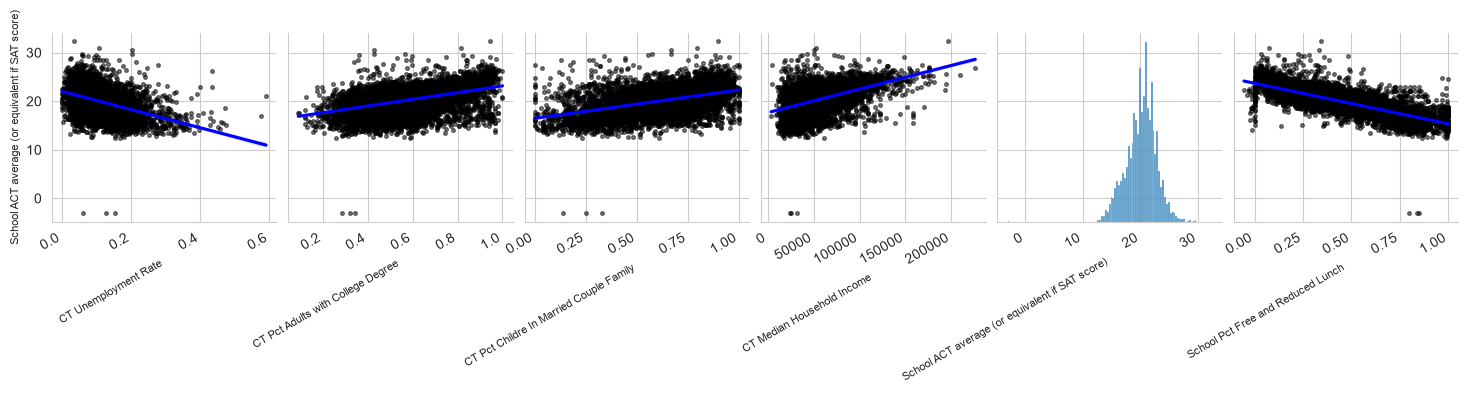

In [154]:
fig = sns.pairplot(
    edgap.drop(columns = 'NCESSCH School ID'),
    y_vars = ['School ACT average (or equivalent if SAT score)'],
    kind = 'reg',
    plot_kws = {
        'line_kws': {'color': 'blue'},
        'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}
    }
)
for ax in fig.axes.flat:
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')
plt.show()

# Data preparation
The following steps select relevant columns, reduce the long membership and staff records to one row per school, standardize variable names, and align school-ID data types before merging.

In [155]:
school_information = school_information[
    ['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']
]

In [156]:
membership = membership[['NCESSCH', 'TOTAL_INDICATOR', 'STUDENT_COUNT']]

In [157]:
membership.head()

,NCESSCH,TOTAL_INDICATOR,STUDENT_COUNT
0,10000200277,Category Set A - By Race/Ethnicity; Sex; Grade,NaN
1,10000200277,Category Set A - By Race/Ethnicity; Sex; Grade,NaN
2,10000200277,Category Set A - By Race/Ethnicity; Sex; Grade,NaN
3,10000200277,Category Set A - By Race/Ethnicity; Sex; Grade,NaN
4,10000200277,Category Set A - By Race/Ethnicity; Sex; Grade,NaN


In [158]:
total = membership[membership['TOTAL_INDICATOR'].str.contains('minus Adult Education Count')]
print(total.head())
print(total['STUDENT_COUNT'].describe())

        NCESSCH                                    TOTAL_INDICATOR  \
91  10000200277  Derived - Education Unit Total minus Adult Edu...   
92  10000200277  Derived - Subtotal by Race/Ethnicity and Sex m...   
93  10000200277  Derived - Subtotal by Race/Ethnicity and Sex m...   
94  10000200277  Derived - Subtotal by Race/Ethnicity and Sex m...   
95  10000200277  Derived - Subtotal by Race/Ethnicity and Sex m...   

    STUDENT_COUNT  
91            NaN  
92            NaN  
93            NaN  
94            NaN  
95            NaN  
count    1.396117e+06
mean     7.267110e+01
std      1.918520e+02
min      0.000000e+00
25%      0.000000e+00
50%      5.000000e+00
75%      4.800000e+01
max      1.431900e+04
Name: STUDENT_COUNT, dtype: float64


In [159]:
ind = membership['TOTAL_INDICATOR'].astype(str)
total = membership[ind.str.contains('Education Unit Total') & ind.str.contains('minus Adult Education Count')]
print(total.shape)
print(total['STUDENT_COUNT'].describe())

(99070, 3)
count    98563.000000
mean       514.733744
std        452.016547
min          0.000000
25%        243.000000
50%        434.000000
75%        654.000000
max      14319.000000
Name: STUDENT_COUNT, dtype: float64


## Reduce the long membership and staff files to one row per school
Membership and staff files can contain multiple rows for each school because they report different categories or measures. The following code selects the appropriate total records and aggregates the information to school level so that the later joins do not unintentionally multiply rows.

In [160]:
indicator = membership['TOTAL_INDICATOR'].astype(str)
total_rows = (indicator.str.contains('Education Unit Total', na = False)
              & indicator.str.contains('minus Adult Education Count', na = False))

enrollment = (
    membership.loc[total_rows, ['NCESSCH', 'STUDENT_COUNT']]
    .rename(columns = {'NCESSCH': 'id', 'STUDENT_COUNT': 'enrollment'})
)


teachers = (
    staff[['NCESSCH', 'TEACHERS']]
    .rename(columns = {'NCESSCH': 'id', 'TEACHERS': 'teacher_fte'})
)

print(enrollment.shape, teachers.shape)

(99070, 2) (100062, 2)


## Rename columns
Makes the columns easier to understand

In [161]:
edgap = edgap.rename(columns = {
    'NCESSCH School ID': 'id',
    'CT Unemployment Rate': 'rate_unemployment',
    'CT Pct Adults with College Degree': 'percent_college',
    'CT Pct Childre In Married Couple Family': 'percent_married',
    'CT Median Household Income': 'median_income',
    'School ACT average (or equivalent if SAT score)': 'average_act',
    'School Pct Free and Reduced Lunch': 'percent_lunch',
})
school_information = school_information.rename(columns = {
    'NCESSCH': 'id',
    'SCHOOL_YEAR': 'year',
    'LSTATE': 'state',
    'LZIP': 'zip_code',
    'SCH_TYPE_TEXT': 'school_type',
    'LEVEL': 'school_level',
    'CHARTER_TEXT': 'charter',
})

## Convert data types so the join keys match
identifiers need to be of same type to merge successfully

In [162]:
def id_to_object(frame):
    frame = frame.dropna(subset = ['id']).copy()
    frame['id'] = frame['id'].astype('int64').astype('object')
    return frame

school_information = id_to_object(school_information)
enrollment = id_to_object(enrollment)
teachers = id_to_object(teachers)

edgap['id'] = edgap['id'].astype(str).str.strip().astype('int64').astype('object')

## Join alll data frames
merge the data tables using the identifiers

In [163]:
df = (
    edgap
    .merge(school_information, how = 'left', on = 'id')
    .merge(enrollment, how = 'left', on = 'id')
    .merge(teachers, how = 'left', on = 'id')
)
print(df.shape)
df.info()

(7986, 15)
<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   str    
 8   state              7898 non-null   str    
 9   zip_code           7898 non-null   str    
 10  school_type        7898 non-null   str    
 11  school_level       7898 non-null   str    
 12  charter            7898 non-null   str    
 13  enrollment         7860 non-null   float64
 14  teacher_fte        7852 non-null   float64
dtypes: float64(8), object(1), str(6)
memory usage: 936.0+ KB


In [164]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,enrollment,teacher_fte
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,584.0,25.0
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,1499.0,87.0
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,1638.0,95.0
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,1406.0,98.0
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,1996.0,134.0


In [165]:
df.describe().round(3)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,enrollment,teacher_fte
count,7972.000,7973.000,7961.000,7966.000,7986.000,7986.000,7860.000,7852.000
mean,0.099,0.569,0.633,52026.905,20.182,0.421,1003.686,61.225
std,0.059,0.166,0.197,24228.057,2.595,0.240,785.065,43.389
min,0.000,0.091,0.000,3589.000,-3.071,-0.055,0.000,0.000
25%,0.059,0.451,0.524,36597.250,18.600,0.239,419.000,28.010
50%,0.086,0.555,0.668,46833.500,20.400,0.382,766.000,49.000
75%,0.123,0.677,0.777,61369.250,21.911,0.575,1400.000,84.395
max,0.590,1.000,1.000,226181.000,32.363,0.999,12033.000,570.100


## Set out-of-range values to NaN
convertimplausible values in selected percentage and ACT variables to missing values rather than allowing them to distort the analysis.

In [166]:
df.loc[df['percent_lunch'] < 0, 'percent_lunch'] = np.nan
df.loc[df['percent_lunch'] > 1, 'percent_lunch'] = np.nan  
df.loc[df['average_act'] < 1, 'average_act'] = np.nan
df.loc[df['average_act'] > 36, 'average_act'] = np.nan      
df.loc[df['enrollment'] <= 0, 'enrollment'] = np.nan
df.loc[df['teacher_fte'] <= 0, 'teacher_fte'] = np.nan

## Check school types and keep only high schools


In [167]:
print(df['school_type'].value_counts(dropna = False))
print(df['school_level'].value_counts(dropna = False))
print(df['charter'].value_counts(dropna = False))

school_type
Regular School                 7885
NaN                              88
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64
school_level
High            7230
Other            631
NaN               88
Not reported      35
Elementary         2
Name: count, dtype: int64
charter
No                7329
Yes                352
Not applicable     217
NaN                 88
Name: count, dtype: int64


In [168]:
df = df.loc[df['school_level'] == 'High'].copy()

In [169]:
print(df['school_type'].value_counts(dropna = False))
print(df['school_level'].value_counts(dropna = False))
print(df['charter'].value_counts(dropna = False))

school_type
Regular School                 7218
Alternative School                9
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64
school_level
High    7230
Name: count, dtype: int64
charter
No                6861
Not applicable     199
Yes                170
Name: count, dtype: int64


In [170]:
print('duplicate rows:', df.duplicated().sum())
print('duplicate school ids:', df['id'].duplicated().sum())
df = df.drop_duplicates(subset = 'id')

duplicate rows: 0
duplicate school ids: 0


# Derived variables
The next cell derives the student–teacher ratio, log enrollment, and a large-school indicator. The ratio expresses enrollment relative to teacher full-time equivalents; log enrollment reduces the influence of the right-skewed enrollment distribution; and the large-school indicator supports a simple group comparison in the exploratory plots.

- `student_teacher_ratio` = enrollment / teacher FTE: how many students each teacher serves.
- `log_enrollment`: enrollment is right-skewed, so the log gives a more linear relationship.
- `large_school`: indicator for schools above the median enrollment (used for plotting).

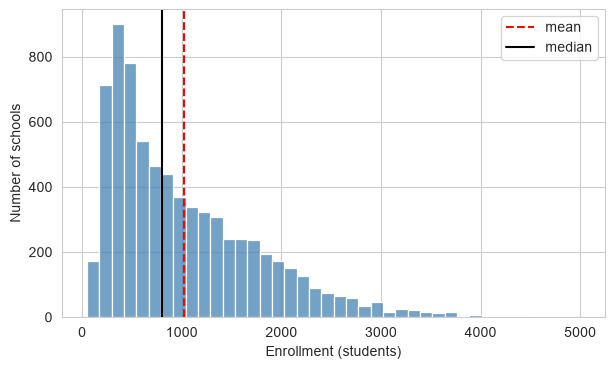

In [171]:
plt.figure(figsize = (7, 4))
sns.histplot(df['enrollment'], bins = 40, color = 'steelblue')
plt.axvline(df['enrollment'].mean(), color = 'r', linestyle = '--', label = 'mean')
plt.axvline(df['enrollment'].median(), color = 'k', linestyle = '-', label = 'median')
plt.xlabel('Enrollment (students)')
plt.ylabel('Number of schools')
plt.legend()
plt.show()

In [172]:
df['student_teacher_ratio'] = df['enrollment'] / df['teacher_fte']

# a ratio above 60 or below 3 is almost certainly a data error
df.loc[(df['student_teacher_ratio'] > 60) | (df['student_teacher_ratio'] < 3),
       'student_teacher_ratio'] = np.nan

df['log_enrollment'] = np.log(df['enrollment'])
df['large_school'] = np.where(df['enrollment'] > df['enrollment'].median(), 'Large', 'Small')
df.loc[df['enrollment'].isna(), 'large_school'] = np.nan

df[['enrollment', 'teacher_fte', 'student_teacher_ratio', 'log_enrollment']].describe().round(2)

,enrollment,teacher_fte,student_teacher_ratio,log_enrollment
count,7227.00,7216.00,7206.00,7227.00
mean,1020.84,62.33,16.18,6.65
std,759.23,43.25,3.90,0.78
min,48.00,0.50,4.25,3.87
25%,422.00,28.21,13.56,6.05
50%,801.00,50.82,15.88,6.69
75%,1443.00,86.51,18.42,7.27
max,5000.00,291.00,57.20,8.52


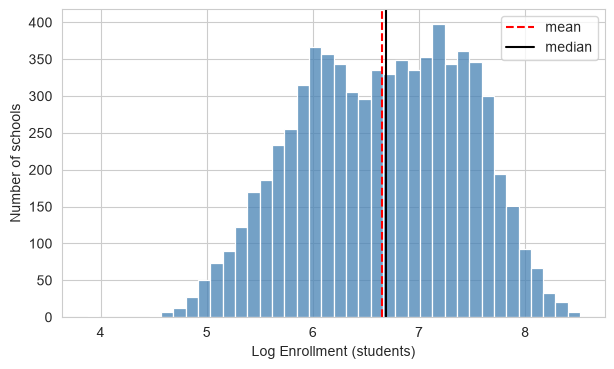

In [173]:
plt.figure(figsize = (7, 4))
sns.histplot(df['log_enrollment'], bins = 40, color = 'steelblue')
plt.axvline(df['log_enrollment'].mean(), color = 'r', linestyle = '--', label = 'mean')
plt.axvline(df['log_enrollment'].median(), color = 'k', linestyle = '-', label = 'median')
plt.xlabel('Log Enrollment (students)')
plt.ylabel('Number of schools')
plt.legend()
plt.show()

##  Missing values


In [174]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


20 states


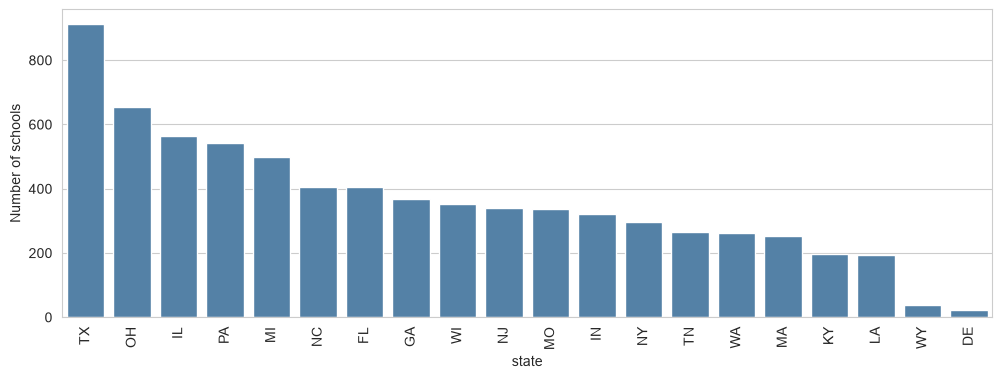

In [175]:
state_counts = df['state'].value_counts()
print(state_counts.shape[0], 'states')
plt.figure(figsize = (12, 4))
sns.barplot(x = state_counts.index, y = state_counts.values, color = 'steelblue')
plt.xticks(rotation = 90)
plt.ylabel('Number of schools')
plt.show()

In [176]:
df = df.dropna(subset = ['average_act']).copy()

# Impute missing predictor values

In [177]:
numeric_predictors = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'log_enrollment',
    'student_teacher_ratio',
]
imputer = IterativeImputer(random_state = 0)
imputer.fit(df[numeric_predictors])
df[numeric_predictors] = imputer.transform(df[numeric_predictors])
df['enrollment'] = np.exp(df['log_enrollment'])
df[numeric_predictors + ['average_act']].isna().sum()

rate_unemployment        0
percent_college          0
percent_married          0
median_income            0
percent_lunch            0
log_enrollment           0
student_teacher_ratio    0
average_act              0
dtype: int64

In [178]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


# Export the clean data set
The cleaned school-level dataset is exported as education_clean.csv for reuse.

In [179]:
df.to_csv('education_clean.csv', encoding = 'utf-8-sig', index = False)
print(df.shape)
df.head()

(7227, 18)


,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,enrollment,teacher_fte,student_teacher_ratio,log_enrollment,large_school
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,584.0,25.0,23.360000,6.369901,Small
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,1499.0,87.0,17.229885,7.312553,Large
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,1638.0,95.0,17.242105,7.401231,Large
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,1406.0,98.0,14.346939,7.248504,Large
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,1996.0,134.0,14.895522,7.598900,Large


# Analysis
The analysis first explores the relationships among the variables, then estimates two nested ordinary least squares (OLS) regression models.The baseline model uses socioeconomic predictors only. The full model adds log enrollment and the student–teacher ratio.

## Distributions and correlations
The correlation heatmap summarizes pairwise linear relationships among the numeric predictors and average ACT score. The histograms show the distributions of log enrollment and student–teacher ratio, while the boxplot compares ACT averages between the two school-size groups.

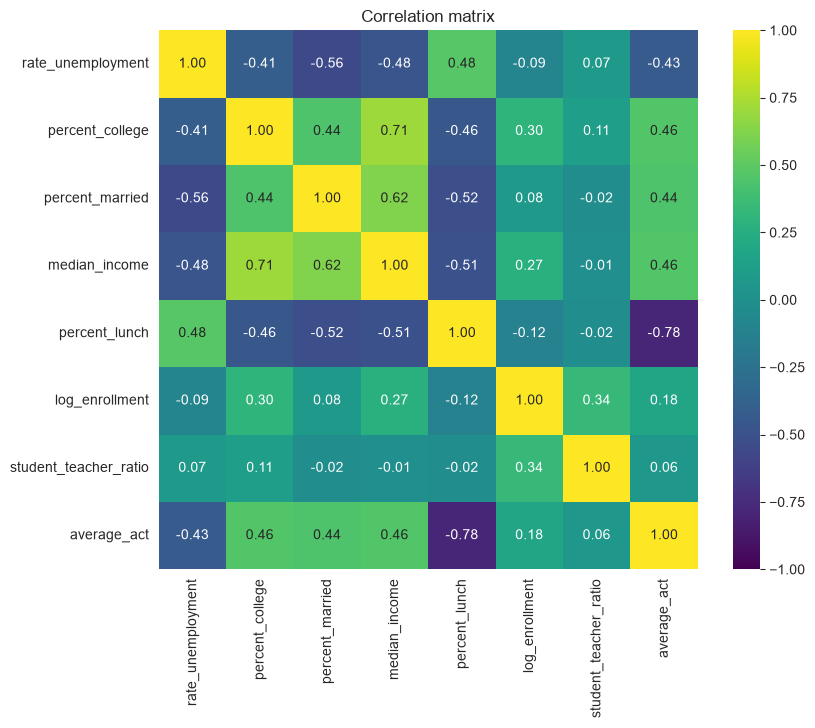

In [180]:
corr_cols = numeric_predictors + ['average_act']
plt.figure(figsize = (9, 7))
sns.heatmap(df[corr_cols].corr(), vmin = -1, vmax = 1, annot = True, fmt = '.2f',
            cmap = 'viridis', square = True)
plt.title('Correlation matrix')
plt.show()

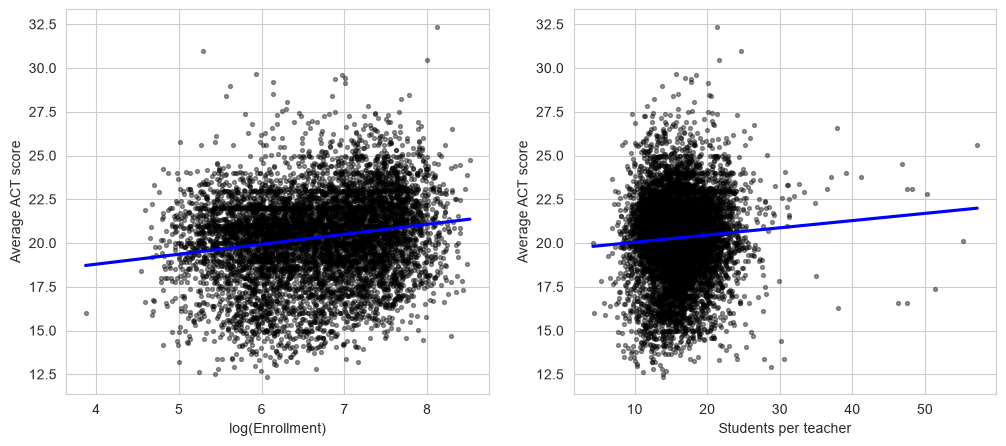

In [181]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5))
for ax, col, label in zip(axes,
                          ['log_enrollment', 'student_teacher_ratio'],
                          ['log(Enrollment)', 'Students per teacher']):
    sns.regplot(data = df, x = col, y = 'average_act', ax = ax, ci = False,
                scatter_kws = {'alpha': 0.4, 's': 8, 'color': 'k'},
                line_kws = {'color': 'blue'})
    ax.set_xlabel(label)
    ax.set_ylabel('Average ACT score')
plt.show()

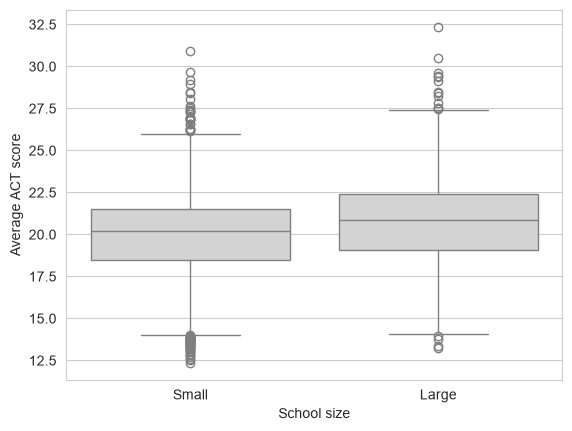

In [182]:
sns.boxplot(data = df, x = 'large_school', y = 'average_act', color = 'lightgray')
plt.xlabel('School size')
plt.ylabel('Average ACT score')
plt.show()

# Baseline: socioeconomic factors only
The baseline OLS model estimates the association between average ACT score and the five socioeconomic predictors: unemployment, adult college attainment, married-couple families, median household income, and free/reduced-price lunch.


In [183]:
ses_terms = 'rate_unemployment + percent_college + percent_married + median_income + percent_lunch'
model_ses = smf.ols(f'average_act ~ {ses_terms}', data = df).fit()
print(model_ses.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2438.
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:14:03   Log-Likelihood:                -13327.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7221   BIC:                         2.671e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.7001      0.13

# Full model: add school size and staffing
The full OLS model includes all five socioeconomic predictors plus log enrollment and the student–teacher ratio. Comparing its fit with the baseline model shows whether the two school-level variables provide additional explanatory value after the socioeconomic variables are held constant.

In [184]:
model_full = smf.ols(
    f'average_act ~ {ses_terms} + log_enrollment + student_teacher_ratio',
    data = df
).fit()
print(model_full.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.632
Model:                            OLS   Adj. R-squared:                  0.632
Method:                 Least Squares   F-statistic:                     1771.
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:14:03   Log-Likelihood:                -13289.
No. Observations:                7227   AIC:                         2.659e+04
Df Residuals:                    7219   BIC:                         2.665e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                21.47

#  Do the new predictors help?

In [185]:
print(anova_lm(model_ses, model_full))

   df_resid           ssr  df_diff     ss_diff          F        Pr(>F)
0    7221.0  16914.955706      0.0         NaN        NaN           NaN
1    7219.0  16735.364172      2.0  179.591534  38.734481  1.851184e-17


## Initial Model-Comparison Interpretation
In the current saved output, the socioeconomic-only model has \(R^2 = 0.628\), while the full model has \(R^2 = 0.632\). The nested-model ANOVA reports \(F = 38.73\) with p approx 1.85 * 10 ^-17, indicating that adding the two school-level predictors improves in-sample fit statistically. The increase in explained variation is nevertheless modest, so statistical significance should not be confused with a large improvement in predictive performance.

In [186]:
def fit_table(models, names):
    rows = []
    for m, n in zip(models, names):
        pred = m.predict(df)
        rows.append({
            'model': n,
            'R-squared': m.rsquared,
            'Adj. R-squared': m.rsquared_adj,
            'AIC': m.aic,
            'MAE': mean_absolute_error(df['average_act'], pred),
            'RMSE': np.sqrt(mean_squared_error(df['average_act'], pred)),
        })
    return pd.DataFrame(rows).set_index('model').round(4)

fit_table([model_ses, model_full], ['socioeconomic only', 'socioeconomic + size + staffing'])

,R-squared,Adj. R-squared,AIC,MAE,RMSE
model,,,,,
socioeconomic only,0.6280,0.6277,26666.9917,1.1453,1.5299
socioeconomic + size + staffing,0.6319,0.6316,26593.8501,1.1365,1.5217


# Reading the Model-Fit Table
R squared increases and mae,rmse decreases statistically these changes favour the full model but their size is small.

# Which predictors matter most? (standardized coefficients)

                         coef  ci_low  ci_high  p_value
rate_unemployment     -0.1407 -0.1855  -0.0958   0.0000
percent_college        0.2407  0.1890   0.2925   0.0000
percent_married        0.0013 -0.0489   0.0515   0.9587
median_income         -0.0209 -0.0795   0.0378   0.4858
percent_lunch         -1.7811 -1.8254  -1.7369   0.0000
log_enrollment         0.1293  0.0897   0.1688   0.0000
student_teacher_ratio  0.0683  0.0302   0.1063   0.0004


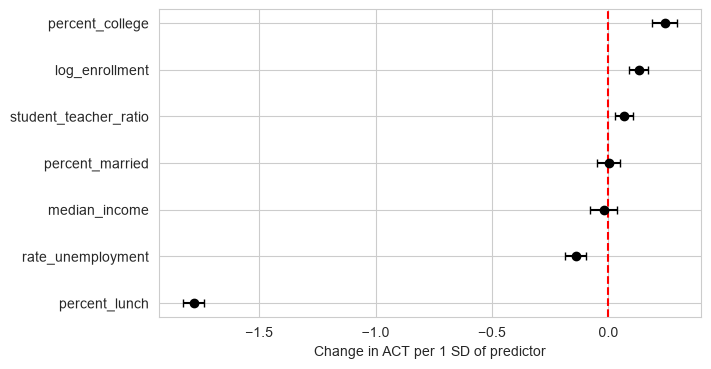

In [187]:
from sklearn.preprocessing import StandardScaler

scaled_cols = [c + '_z' for c in numeric_predictors]
df[scaled_cols] = StandardScaler().fit_transform(df[numeric_predictors])

model_z = smf.ols('average_act ~ ' + ' + '.join(scaled_cols), data = df).fit()
coef = pd.DataFrame({'coef': model_z.params, 'ci_low': model_z.conf_int()[0],
                     'ci_high': model_z.conf_int()[1], 'p_value': model_z.pvalues}).drop('Intercept')
coef.index = [i.replace('_z', '') for i in coef.index]
print(coef.round(4))

plt.figure(figsize = (7, 4))
order = coef['coef'].sort_values().index
plt.errorbar(coef.loc[order, 'coef'], range(len(order)),
             xerr = [coef.loc[order, 'coef'] - coef.loc[order, 'ci_low'],
                     coef.loc[order, 'ci_high'] - coef.loc[order, 'coef']],
             fmt = 'ko', capsize = 3)
plt.yticks(range(len(order)), order)
plt.axvline(0, color = 'r', linestyle = '--')
plt.xlabel('Change in ACT per 1 SD of predictor')
plt.show()

### Interpretation of Standardized Coefficients
The largest absolute standardized coefficient is for the free/reduced-price lunch percentage (about \(-1.78\)), followed by adult college attainment (about \(0.24\)). Log enrollment (about \(0.13\)) and student–teacher ratio (about \(0.07\)) have smaller positive standardized coefficients in this model.

##  Residual diagnostics
The residual-versus-fitted plot is used to assess whether residuals are centered around zero and whether their spread changes across fitted ACT values

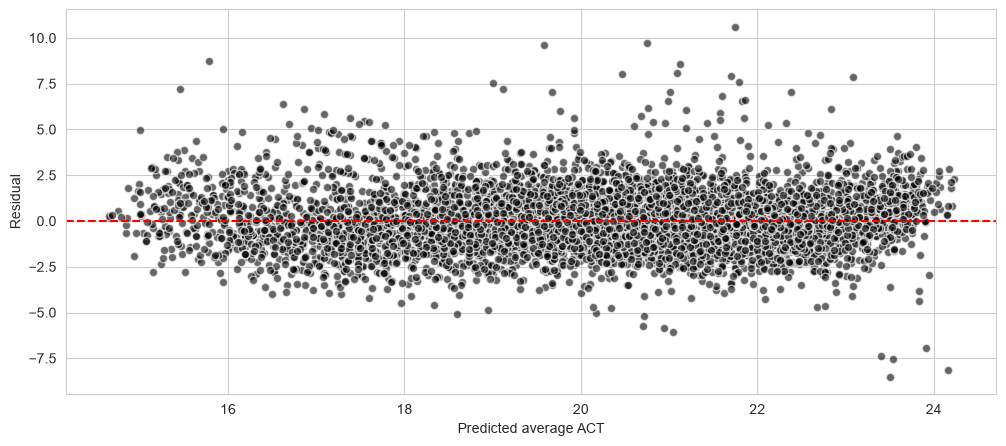

In [188]:
fig, axes = plt.subplots(figsize = (12, 5))
axes.plot(model_full.fittedvalues, model_full.resid, 'ko', mec = 'w', alpha = 0.6)
axes.axhline(0, color = 'r', linestyle = '--')
axes.set_xlabel('Predicted average ACT')
axes.set_ylabel('Residual')

plt.show()

## Robustness: control for state and charter status
States differ in ACT participation and reporting practices, so state-level differences may be associated with average school ACT scores. This robustness model adds state and charter-status indicators while retaining the socioeconomic predictors, enrollment, and student–teacher ratio.
The purpose is to check whether the estimated relationships for school size and staffing remain after accounting for these additional group differences.

In [189]:
model_state = smf.ols(
    f'average_act ~ {ses_terms} + log_enrollment + student_teacher_ratio + C(state) + C(charter)',
    data = df
).fit()

keep = ['log_enrollment', 'student_teacher_ratio']
print(pd.DataFrame({'coef': model_state.params[keep], 'p_value': model_state.pvalues[keep]}).round(4))
print('R-squared with state + charter:', round(model_state.rsquared, 4))

                         coef  p_value
log_enrollment         0.1375      0.0
student_teacher_ratio  0.0383      0.0
R-squared with state + charter: 0.684


# Robustness-Check Interpretation

In the saved output for the model that controls for state and charter status, the coefficients for log enrollment (about \(0.138\)) and student–teacher ratio (about \(0.038\)) remain positive, with reported p-values rounded to 0.0. The model reports r-squared 0.684 . This suggests that the positive conditional associations for these two variables persist after the additional controls, although the interpretation remains observational.